In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
sns.set_theme(style="darkgrid")
plt.rcParams['figure.figsize'] = (14, 7)

In [ ]:
df = pd.read_csv('/content/nifty50.csv')
df

,index,date,time,open,high,low,close
0,NIFTY,20130401,09:16,5701.15,5704.65,5694.30,5697.00
1,NIFTY,20130401,09:17,5697.05,5698.35,5695.65,5697.50
2,NIFTY,20130401,09:18,5697.90,5697.90,5690.60,5692.15
3,NIFTY,20130401,09:19,5691.65,5694.70,5691.65,5693.90
4,NIFTY,20130401,09:20,5694.40,5695.05,5693.35,5694.55
...,...,...,...,...,...,...,...
352915,NIFTY,20160930,15:26,8618.00,8619.85,8617.65,8618.50
352916,NIFTY,20160930,15:27,8618.45,8618.95,8617.25,8617.25
352917,NIFTY,20160930,15:28,8617.20,8618.65,8616.85,8617.50
352918,NIFTY,20160930,15:29,8617.40,8618.80,8615.60,8616.65


In [ ]:
df['datetime'] = pd.to_datetime(df['date'].astype(str) + ' ' + df['time'], format='%Y%m%d %H:%M')

df.set_index('datetime', inplace=True)
df.drop(columns=['index', 'date', 'time'], inplace=True)

df.head()

,open,high,low,close
datetime,,,,
2013-04-01 09:16:00,5701.15,5704.65,5694.30,5697.00
2013-04-01 09:17:00,5697.05,5698.35,5695.65,5697.50
2013-04-01 09:18:00,5697.90,5697.90,5690.60,5692.15
2013-04-01 09:19:00,5691.65,5694.70,5691.65,5693.90
2013-04-01 09:20:00,5694.40,5695.05,5693.35,5694.55


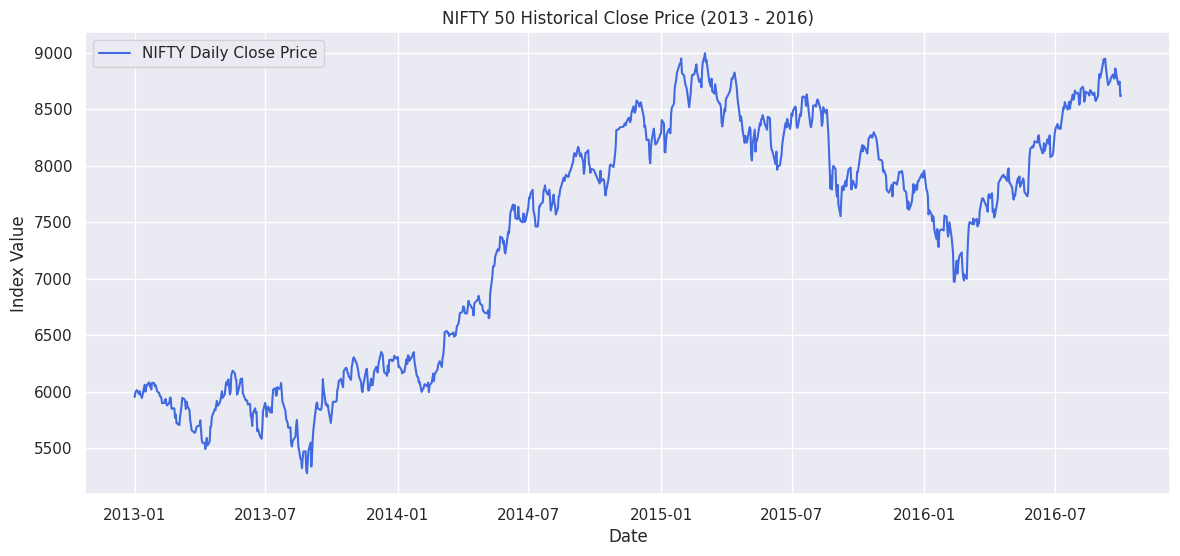

In [ ]:

# Resample 1-minute data into Daily OHLC data
daily_df = df.resample('D').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last'
}).dropna()

# Plot Daily Closing Price
plt.figure(figsize=(14, 6))
plt.plot(daily_df['close'], label='NIFTY Daily Close Price', color='royalblue')
plt.title('NIFTY 50 Historical Close Price (2013 - 2016)')
plt.xlabel('Date')
plt.ylabel('Index Value')
plt.legend()
plt.show()

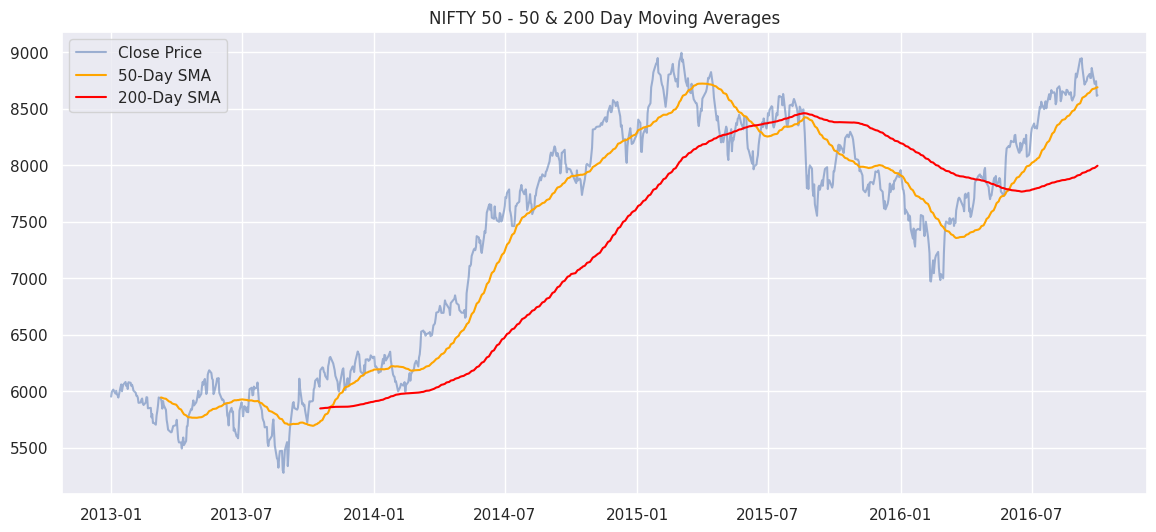

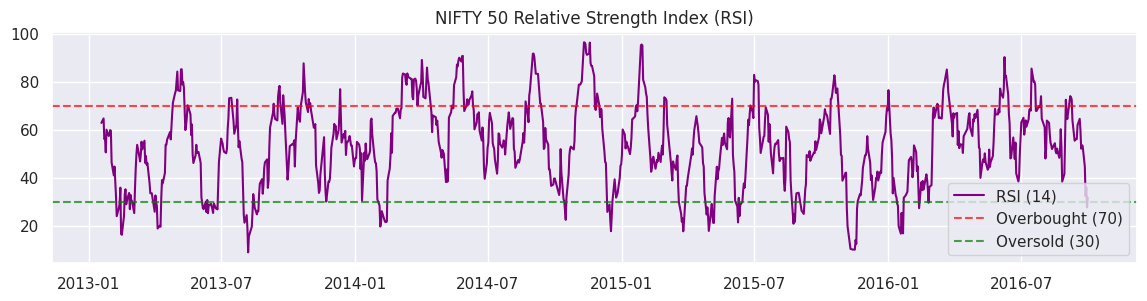

In [ ]:
# Simple Moving Averages
daily_df['SMA_50'] = daily_df['close'].rolling(window=50).mean()
daily_df['SMA_200'] = daily_df['close'].rolling(window=200).mean()

# Relative Strength Index (RSI - 14 Days)
delta = daily_df['close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / loss
daily_df['RSI'] = 100 - (100 / (1 + rs))

# Visualizing Moving Averages
plt.figure(figsize=(14, 6))
plt.plot(daily_df['close'], label='Close Price', alpha=0.5)
plt.plot(daily_df['SMA_50'], label='50-Day SMA', color='orange')
plt.plot(daily_df['SMA_200'], label='200-Day SMA', color='red')
plt.title('NIFTY 50 - 50 & 200 Day Moving Averages')
plt.legend()
plt.show()

# Visualizing RSI
plt.figure(figsize=(14, 3))
plt.plot(daily_df['RSI'], label='RSI (14)', color='purple')
plt.axhline(70, linestyle='--', color='red', alpha=0.7, label='Overbought (70)')
plt.axhline(30, linestyle='--', color='green', alpha=0.7, label='Oversold (30)')
plt.title('NIFTY 50 Relative Strength Index (RSI)')
plt.legend()
plt.show()

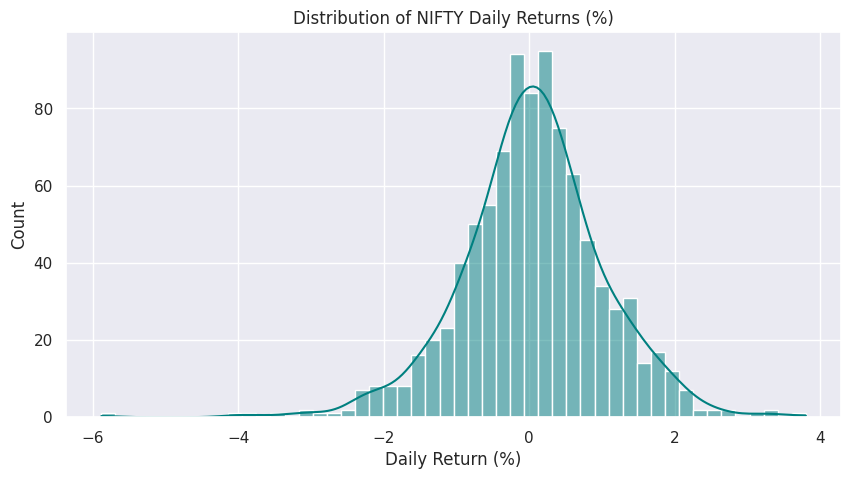

Average Daily Return: 0.04%
Annualized Volatility: 15.67%


In [ ]:
# Daily Percentage Returns
daily_df['Daily_Return'] = daily_df['close'].pct_change() * 100

# Plot Distribution of Daily Returns
plt.figure(figsize=(10, 5))
sns.histplot(daily_df['Daily_Return'].dropna(), kde=True, bins=50, color='teal')
plt.title('Distribution of NIFTY Daily Returns (%)')
plt.xlabel('Daily Return (%)')
plt.show()

# Calculate Summary Metrics
mean_daily_return = daily_df['Daily_Return'].mean()
annualized_volatility = daily_df['Daily_Return'].std() * np.sqrt(252)

print(f"Average Daily Return: {mean_daily_return:.2f}%")
print(f"Annualized Volatility: {annualized_volatility:.2f}%")

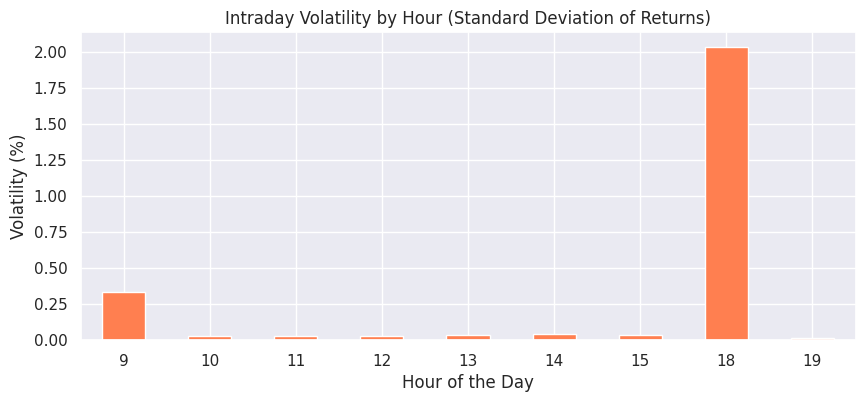

In [ ]:
# Calculate intraday percentage return from min-by-min data
df['Hour'] = df.index.hour
df['Minute_Return'] = df['close'].pct_change()

hourly_volatility = df.groupby('Hour')['Minute_Return'].std() * 100

plt.figure(figsize=(10, 4))
hourly_volatility.plot(kind='bar', color='coral')
plt.title('Intraday Volatility by Hour (Standard Deviation of Returns)')
plt.xlabel('Hour of the Day')
plt.ylabel('Volatility (%)')
plt.xticks(rotation=0)
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 2. Select columns and drop missing values
eval_df = df[['close', 'SMA_50']].dropna()

actual = eval_df['close']
predicted = eval_df['SMA_50']

# 3. Calculate Metrics
mae = mean_absolute_error(actual, predicted)
mse = mean_squared_error(actual, predicted)
rmse = np.sqrt(mse)

# 4. Print results
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

NameError: name 'df' is not defined